# Telecom Customer Churn: Prediction and Profit-Based Retention Targeting

**Business question.** A telecom company loses about a quarter of its customers. The retention team can afford to make offers to
only some customers. **Which customers should get an offer to save the most money?** Prediction accuracy is not enough; the
model has to be turned into a targeting decision with a clear return.

**Data.** IBM *Telco Customer Churn* sample: 7,043 customers, 19 features (demographics, services, contract, billing), churn label.

**Approach**
1. EDA on churn drivers
2. A leak-free scikit-learn `Pipeline` (preprocessing inside cross-validation), stratified 80/20 train/test split
3. Compare Logistic Regression, Random Forest and Gradient Boosting with 5-fold CV (ROC-AUC), then tune the best ones
4. Evaluate on the untouched test set: ROC-AUC, PR-AUC, calibration, lift
5. Explain the model (odds ratios, permutation importance)
6. **Choose who to target by expected profit**, not by a default 0.5 threshold

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.append("../src")
from style import C, apply_style, save

apply_style()
SEED = 42

## 1. Load and clean

In [2]:
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", np.nan))
print(f"Rows: {len(df):,} | blank TotalCharges: {df.TotalCharges.isna().sum()} (all have tenure 0 -> set to 0)")
assert (df.loc[df.TotalCharges.isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["churn"] = (df["Churn"] == "Yes").astype(int)
print(f"Churn rate: {df.churn.mean():.1%}")

Rows: 7,043 | blank TotalCharges: 11 (all have tenure 0 -> set to 0)
Churn rate: 26.5%


## 2. What drives churn?

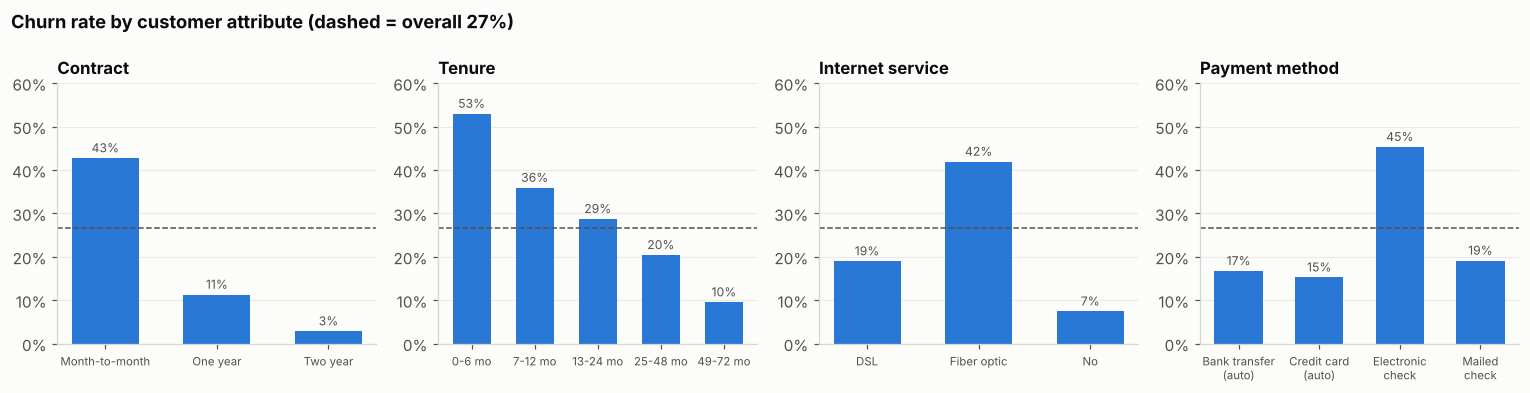

In [3]:
df["tenure_band"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"])
views = {"Contract": "Contract", "tenure_band": "Tenure", "InternetService": "Internet service", "PaymentMethod": "Payment method"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (col, label) in zip(axes, views.items()):
    r = df.groupby(col, observed=True)["churn"].mean()
    labels = [str(i).replace(" (automatic)", "\n(auto)").replace("Electronic check", "Electronic\ncheck").replace("Mailed check", "Mailed\ncheck")
              for i in r.index]
    bars = ax.bar(labels, r.values, color=C["blue"], width=0.6)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in r.values], padding=2, fontsize=8, color=C["ink2"])
    ax.axhline(df.churn.mean(), color=C["ink2"], ls="--", lw=1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_ylim(0, 0.6)
    ax.set_title(label, fontsize=11)
    ax.tick_params(axis="x", labelsize=7.5, rotation=0)
fig.suptitle(f"Churn rate by customer attribute (dashed = overall {df.churn.mean():.0%})", x=0.01, ha="left", fontweight="bold")
save(fig, "01_churn_drivers")
plt.show()

Month-to-month contracts, new customers (first 6 months), fibre-optic internet and electronic-cheque payment have the highest churn.

## 3. Modelling setup

In [4]:
target = "churn"
drop = ["customerID", "Churn", "churn", "tenure_band"]
X = df.drop(columns=drop)
y = df[target]
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train {len(X_train):,} | Test {len(X_test):,} | churn rate train {y_train.mean():.1%}, test {y_test.mean():.1%}")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train 5,634 | Test 1,409 | churn rate train 26.5%, test 26.5%


## 4. Compare models (5-fold CV on the training set)

In [5]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED),
}
cv_scores = {}
for name, model in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_scores[name] = scores
    print(f"{name:<20} ROC-AUC {scores.mean():.3f} ± {scores.std():.3f}")

Logistic Regression  ROC-AUC 0.846 ± 0.013


Random Forest        ROC-AUC 0.845 ± 0.010


Gradient Boosting    ROC-AUC 0.836 ± 0.005


### Tune the two strongest models

In [6]:
lr_search = GridSearchCV(
    Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000))]),
    {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}, cv=cv, scoring="roc_auc", n_jobs=-1,
).fit(X_train, y_train)
gb_search = GridSearchCV(
    Pipeline([("prep", preprocess), ("model", HistGradientBoostingClassifier(random_state=SEED))]),
    {"model__learning_rate": [0.03, 0.06], "model__max_depth": [2, 3, 4], "model__max_iter": [200, 400],
     "model__l2_regularization": [0.0, 1.0]},
    cv=cv, scoring="roc_auc", n_jobs=-1,
).fit(X_train, y_train)
print(f"Logistic Regression best CV AUC {lr_search.best_score_:.3f} with {lr_search.best_params_}")
print(f"Gradient Boosting   best CV AUC {gb_search.best_score_:.3f} with {gb_search.best_params_}")

Logistic Regression best CV AUC 0.846 with {'model__C': 3}
Gradient Boosting   best CV AUC 0.849 with {'model__l2_regularization': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__max_iter': 400}


## 5. Evaluate on the untouched test set

In [7]:
models = {"Logistic Regression": lr_search.best_estimator_, "Gradient Boosting": gb_search.best_estimator_}
test_rows = []
probs = {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    probs[name] = p
    test_rows.append({"model": name, "roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p),
                      "brier": brier_score_loss(y_test, p)})
test_results = pd.DataFrame(test_rows).set_index("model")
test_results.round(3)

,roc_auc,pr_auc,brier
model,,,
Logistic Regression,0.842,0.630,0.138
Gradient Boosting,0.844,0.662,0.136


**Gradient boosting is chosen** because it had the best cross-validated AUC on the training data (the choice is made on CV,
not on the test set). The test set confirms it: slightly higher ROC-AUC and PR-AUC and a lower Brier score (better-calibrated
probabilities, which matters because the profit calculation uses them directly). Logistic regression is kept as an
**interpretable companion model** for explaining churn drivers to the retention team.

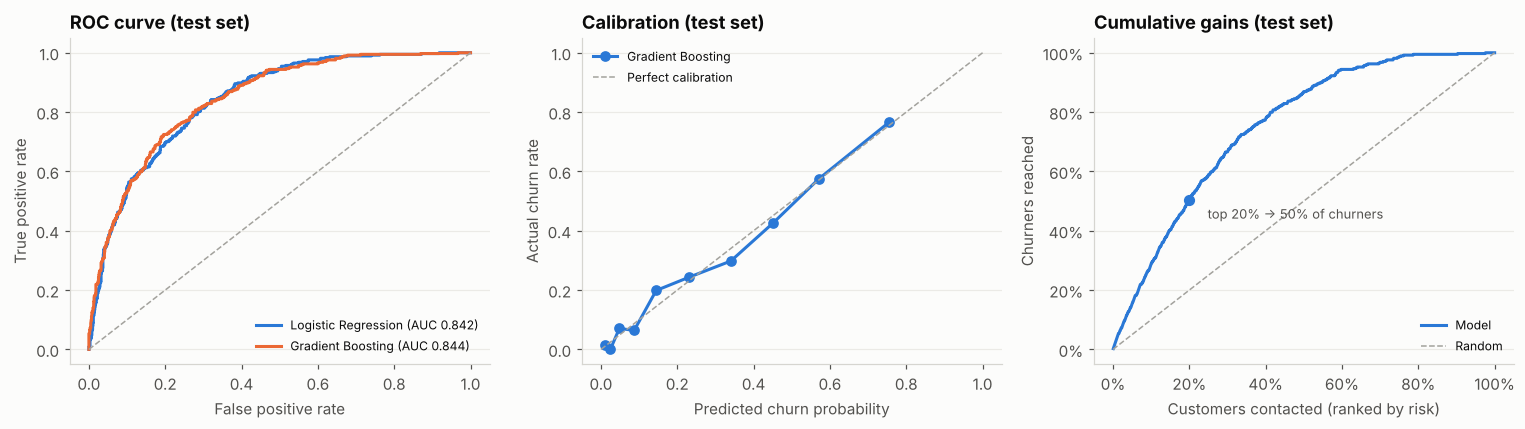

Contacting the riskiest 20% of customers reaches 50% of churners (lift 2.5x).


In [8]:
best_name = "Gradient Boosting"
best = models[best_name]
p_test = probs[best_name]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, (name, p) in enumerate(probs.items()):
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=[C["blue"], C["orange"]][i], label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=C["grey"], ls="--", lw=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (test set)"); axes[0].legend(loc="lower right", fontsize=8)

frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
axes[1].plot(mean_pred, frac_pos, marker="o", color=C["blue"], label=best_name)
axes[1].plot([0, 1], [0, 1], color=C["grey"], ls="--", lw=1, label="Perfect calibration")
axes[1].set_xlabel("Predicted churn probability"); axes[1].set_ylabel("Actual churn rate")
axes[1].set_title("Calibration (test set)"); axes[1].legend(loc="upper left", fontsize=8)

order = np.argsort(-p_test)
captured = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)
axes[2].plot(share, captured, color=C["blue"], label="Model")
axes[2].plot([0, 1], [0, 1], color=C["grey"], ls="--", lw=1, label="Random")
top20 = captured[int(0.2 * len(order)) - 1]
axes[2].scatter([0.2], [top20], color=C["blue"], zorder=3, s=40)
axes[2].annotate(f"top 20% → {top20:.0%} of churners", (0.2, top20), xytext=(12, -12), textcoords="offset points", fontsize=8.5, color=C["ink2"])
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[2].set_xlabel("Customers contacted (ranked by risk)"); axes[2].set_ylabel("Churners reached")
axes[2].set_title("Cumulative gains (test set)"); axes[2].legend(loc="lower right", fontsize=8)
save(fig, "02_model_evaluation")
plt.show()
print(f"Contacting the riskiest 20% of customers reaches {top20:.0%} of churners (lift {top20 / 0.2:.1f}x).")

## 6. What does the model say drives churn?

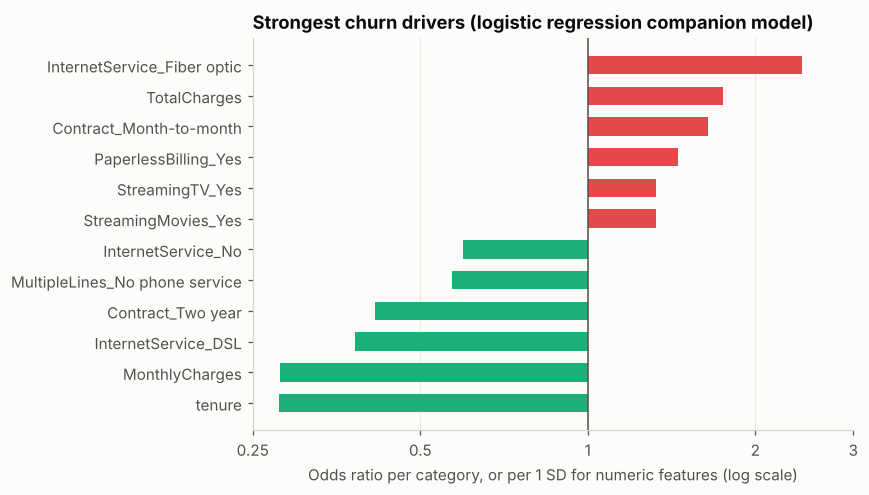

In [9]:
lr = lr_search.best_estimator_  # interpretable companion model
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
odds = np.exp(coefs).sort_values()
odds.index = odds.index.str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([odds.head(6), odds.tail(6)])
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values - 1, left=1, color=[C["aqua"] if v < 1 else C["red"] for v in top.values], height=0.6)
ax.axvline(1, color=C["ink2"], lw=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 3], ["0.25", "0.5", "1", "2", "3"])
ax.minorticks_off()
ax.set_xlabel("Odds ratio per category, or per 1 SD for numeric features (log scale)")
ax.set_title("Strongest churn drivers (logistic regression companion model)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
save(fig, "03_odds_ratios")
plt.show()

Fibre-optic internet, month-to-month contracts and paperless billing raise churn odds; two-year contracts, DSL and long tenure
lower them. **Caution:** `TotalCharges` is roughly `tenure × MonthlyCharges`, so the three numeric coefficients are strongly
correlated and should be read together, not one at a time. The categorical drivers are the safer ones to explain to stakeholders.

Permutation importance for the chosen gradient-boosting model: how much test AUC drops when each feature is shuffled.

In [10]:
perm = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(8).rename("AUC drop when shuffled").round(4)

tenure             0.0644
Contract           0.0538
InternetService    0.0162
OnlineSecurity     0.0055
TechSupport        0.0036
MultipleLines      0.0029
TotalCharges       0.0029
PaymentMethod      0.0027
Name: AUC drop when shuffled, dtype: float64

## 7. Who should get a retention offer? Profit-based targeting

**Assumptions (stated so the business can change them):**

| Assumption | Value |
|---|---|
| Cost of an offer per targeted customer | $50 |
| Chance the offer saves a customer who would have churned | 30% |
| Value of a saved customer | 12 months of their monthly charges |

For each probability threshold, campaign profit = `saved churners' value − offer cost × customers targeted`.

**To avoid tuning on the test set**, the threshold is chosen on *out-of-fold* predictions for the training customers
(5-fold `cross_val_predict`) and then applied, unchanged, to the test set.

Threshold chosen on training out-of-fold predictions: 0.19


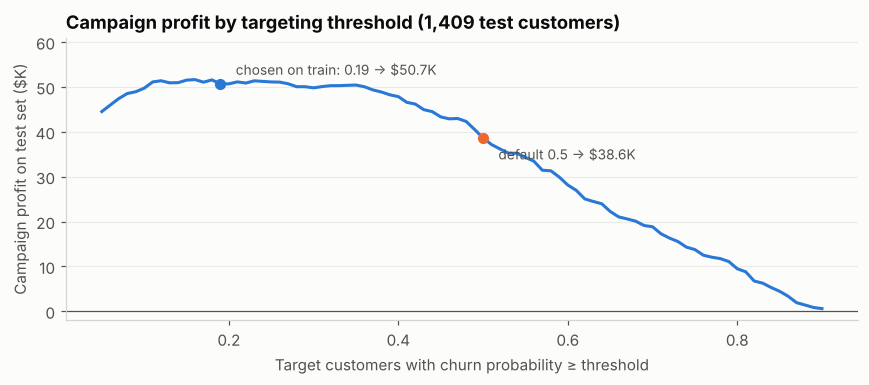

(For reference, the best threshold in hindsight on the test set is 0.16 -> $51,634, so the train-chosen threshold captures 98% of the achievable profit.)


,customers_targeted,profit_usd
Target everyone,"1,409","$27,524"
Default threshold 0.5,283,"$38,626"
Profit-based threshold 0.19,688,"$50,678"


In [11]:
from sklearn.model_selection import cross_val_predict

OFFER_COST, SAVE_RATE, MONTHS = 50, 0.30, 12


def campaign_profit(threshold, p, y_true, monthly, offer_cost=OFFER_COST, save_rate=SAVE_RATE):
    target = p >= threshold
    value_saved = (save_rate * MONTHS * monthly[target & (y_true == 1)]).sum()
    return value_saved - offer_cost * target.sum(), int(target.sum())


def best_threshold(p, y_true, monthly, offer_cost=OFFER_COST, save_rate=SAVE_RATE):
    grid = [(t, campaign_profit(t, p, y_true, monthly, offer_cost, save_rate)[0]) for t in thresholds]
    return max(grid, key=lambda z: z[1])[0]


thresholds = np.round(np.arange(0.05, 0.91, 0.01), 2)
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
m_train, y_tr = X_train["MonthlyCharges"].to_numpy(), y_train.to_numpy()
m_test, yt = X_test["MonthlyCharges"].to_numpy(), y_test.to_numpy()

t_star = best_threshold(oof, y_tr, m_train)
print(f"Threshold chosen on training out-of-fold predictions: {t_star:.2f}")

curve = pd.DataFrame([(t, *campaign_profit(t, p_test, yt, m_test)) for t in thresholds], columns=["threshold", "profit", "targeted"])
chosen = curve.loc[curve["threshold"] == t_star].iloc[0]
default = curve.loc[curve["threshold"] == 0.5].iloc[0]
everyone = campaign_profit(0.0, p_test, yt, m_test)
oracle = curve.loc[curve["profit"].idxmax()]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curve["threshold"], curve["profit"] / 1e3, color=C["blue"])
ax.scatter([t_star], [chosen.profit / 1e3], color=C["blue"], zorder=3, s=40)
ax.annotate(f"chosen on train: {t_star:.2f} → ${chosen.profit/1e3:.1f}K", (t_star, chosen.profit / 1e3),
            xytext=(10, 6), textcoords="offset points", fontsize=9, color=C["ink2"])
ax.scatter([0.5], [default.profit / 1e3], color=C["orange"], zorder=3, s=40)
ax.annotate(f"default 0.5 → ${default.profit/1e3:.1f}K", (0.5, default.profit / 1e3), xytext=(10, -14),
            textcoords="offset points", fontsize=9, color=C["ink2"])
ax.axhline(0, color=C["ink2"], lw=0.8)
ax.set_ylim(-2, curve["profit"].max() / 1e3 * 1.18)
ax.set_xlabel("Target customers with churn probability ≥ threshold")
ax.set_ylabel("Campaign profit on test set ($K)")
ax.set_title(f"Campaign profit by targeting threshold ({len(X_test):,} test customers)")
save(fig, "04_profit_by_threshold")
plt.show()

summary = pd.DataFrame({
    "customers_targeted": [everyone[1], int(default.targeted), int(chosen.targeted)],
    "profit_usd": [everyone[0], default.profit, chosen.profit],
}, index=["Target everyone", "Default threshold 0.5", f"Profit-based threshold {t_star:.2f}"])
print(f"(For reference, the best threshold in hindsight on the test set is {oracle.threshold:.2f} -> ${oracle.profit:,.0f}, "
      f"so the train-chosen threshold captures {chosen.profit/oracle.profit:.0%} of the achievable profit.)")
summary.style.format({"customers_targeted": "{:,}", "profit_usd": "${:,.0f}"})

### Sensitivity: does the recommendation survive different assumptions?
For each scenario the threshold is again chosen on the training out-of-fold predictions and evaluated on the test set.

In [12]:
rows = []
for save_rate in (0.2, 0.3, 0.4):
    for cost in (30, 50, 80):
        t = best_threshold(oof, y_tr, m_train, cost, save_rate)
        prof = campaign_profit(t, p_test, yt, m_test, cost, save_rate)[0]
        rows.append({"save_rate": save_rate, "offer_cost": cost, "threshold": t, "test_profit_usd": prof,
                     "gain_vs_0.5": prof - campaign_profit(0.5, p_test, yt, m_test, cost, save_rate)[0]})
sens = pd.DataFrame(rows)
print(f"Profit-based threshold beats the 0.5 default in {(sens['gain_vs_0.5'] > 0).sum()} of {len(sens)} scenarios")
sens.style.format({"save_rate": "{:.0%}", "offer_cost": "${}", "threshold": "{:.2f}", "test_profit_usd": "${:,.0f}", "gain_vs_0.5": lambda v: f"+${v:,.0f}" if v >= 0 else f"-${-v:,.0f}"})

Profit-based threshold beats the 0.5 default in 9 of 9 scenarios


,save_rate,offer_cost,threshold,test_profit_usd,gain_vs_0.5
0,20%,$30,0.18,"$36,731","+$10,038"
1,20%,$50,0.33,"$25,209","+$4,175"
2,20%,$80,0.46,"$12,916",+$372
3,30%,$30,0.15,"$66,799","+$22,514"
4,30%,$50,0.19,"$50,678","+$12,053"
5,30%,$80,0.33,"$35,318","+$5,183"
6,40%,$30,0.09,"$98,499","+$36,622"
7,40%,$50,0.16,"$81,145","+$24,927"
8,40%,$80,0.25,"$60,101","+$12,373"


## 8. Save the model and score customers

In [13]:
Path("../models").mkdir(exist_ok=True)
final = gb_search.best_estimator_  # trained on the training split; refit on all data before production use
joblib.dump({"model": final, "threshold": float(t_star), "features": list(X.columns)}, "../models/churn_model.joblib")
scored = X_test.assign(customerID=df.loc[X_test.index, "customerID"], churn_probability=p_test.round(4),
                       target_for_offer=p_test >= t_star)
scored.sort_values("churn_probability", ascending=False)[["customerID", "churn_probability", "target_for_offer", "Contract",
                                                          "tenure", "MonthlyCharges"]].to_csv("../outputs/test_customers_scored.csv", index=False)
print("Saved models/churn_model.joblib and outputs/test_customers_scored.csv")

Saved models/churn_model.joblib and outputs/test_customers_scored.csv


## 9. Summary

In [14]:
tr = test_results.loc[best_name]
print(f"""
- Churn rate {df.churn.mean():.1%}; highest for month-to-month contracts, tenure under 6 months, fibre internet, electronic cheque.
- Best model (by CV): {best_name}: CV AUC {gb_search.best_score_:.3f}; test ROC-AUC {tr.roc_auc:.3f}, PR-AUC {tr.pr_auc:.3f}
  (logistic regression: test ROC-AUC {test_results.loc['Logistic Regression','roc_auc']:.3f}, PR-AUC {test_results.loc['Logistic Regression','pr_auc']:.3f}).
- Contacting the riskiest 20% reaches {top20:.0%} of churners ({top20/0.2:.1f}x lift).
- Profit-based threshold {t_star:.2f} (chosen on training data): ${chosen.profit:,.0f} on the test set vs ${default.profit:,.0f} at 0.5
  (+{(chosen.profit/default.profit-1):.0%}) and ${everyone[0]:,.0f} if everyone is targeted; it targets {int(chosen.targeted)} of {len(X_test):,} customers.
""")


- Churn rate 26.5%; highest for month-to-month contracts, tenure under 6 months, fibre internet, electronic cheque.
- Best model (by CV): Gradient Boosting: CV AUC 0.849; test ROC-AUC 0.844, PR-AUC 0.662
  (logistic regression: test ROC-AUC 0.842, PR-AUC 0.630).
- Contacting the riskiest 20% reaches 50% of churners (2.5x lift).
- Profit-based threshold 0.19 (chosen on training data): $50,678 on the test set vs $38,626 at 0.5
  (+31%) and $27,524 if everyone is targeted; it targets 688 of 1,409 customers.

